# Examen Práctico — Primer Parcial
## Tópicos de Big Data

**Instrucciones generales**

- Este notebook es tu entregable. Complétalo en orden, sin borrar los enunciados.
- Al final debes subir este archivo (`.ipynb`) al repositorio de GitHub del curso, en la carpeta correspondiente a tu nombre/usuario.
- Se evaluará tanto el código (que corra sin errores, de arriba hacia abajo) como tus interpretaciones escritas en las celdas de texto marcadas como *"Interpretación"*.
- Cada quien trabaja con **un dataset distinto**, asignado por la profesora. No copies celdas de un compañero con un dataset diferente: aunque las preguntas se parecen, los datos y las columnas no son las mismas.


## 0. Datos del alumno

Completa la siguiente celda con tus datos y el nombre del dataset que te fue asignado.

In [1]:
# --- COMPLETA CON TUS DATOS ---
# Tu nombre completo
# Tu matrícula o número de cuenta
# Debe ser uno de: "alcohol", "migracion", "desnutricion", "pib", "homicidios"
NOMBRE = "Jorge Adalberto Zuñiga Oliva"
MATRICULA = "82005"
DATASET_ASIGNADO = "pib"
ANIO_NACIMIENTO = 2006
print(f"Alumno: {NOMBRE} | Matrícula: {MATRICULA}")
print(f"Dataset: {DATASET_ASIGNADO} | Año de nacimiento: {ANIO_NACIMIENTO}")

Alumno: Jorge Adalberto Zuñiga Oliva | Matrícula: 82005
Dataset: pib | Año de nacimiento: 2006


## 1. Configuración del entorno virtual (Visual Studio Code)

Antes de instalar librerías directamente en tu sistema, es una buena práctica crear un
**entorno virtual** exclusivo para este examen. Esto evita conflictos de versiones con
otros proyectos y hace que tu entorno de trabajo sea reproducible.

**Requisitos previos en VS Code:** ten instaladas las extensiones oficiales **"Python"**
y **"Jupyter"** (ambas de Microsoft), disponibles en la pestaña de Extensiones (ícono de
cuadritos en la barra lateral izquierda, o `Ctrl+Shift+X` / `Cmd+Shift+X`).

Abre una terminal **dentro de VS Code** (menú **Terminal → New Terminal**, o
`` Ctrl+ñ ``/`` Ctrl+` ``) y verifica que estés ubicado en la carpeta de tu repositorio
del curso (donde vas a guardar este notebook).

### Windows (PowerShell, terminal integrada de VS Code)

```powershell
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python -m venv .venv

# 2. Activar el entorno virtual
.venv\Scripts\Activate.ps1

# Si PowerShell bloquea la ejecución de scripts, ejecuta una sola vez:
#   Set-ExecutionPolicy -Scope CurrentUser RemoteSigned
# y vuelve a intentar activar el entorno.

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

### macOS / Linux (terminal integrada de VS Code, bash o zsh)

```bash
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python3 -m venv .venv

# 2. Activar el entorno virtual
source .venv/bin/activate

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

> **Nota:** usamos el nombre `.venv` (con punto) porque VS Code lo detecta automáticamente
> dentro de la carpeta del proyecto. Si usas Anaconda/Miniconda en lugar de `venv`, el
> equivalente es:
> ```bash
> conda create -n examen-bigdata python=3.11 pandas numpy ipykernel matplotlib requests -y
> conda activate examen-bigdata
> ```

### Seleccionar el entorno virtual como kernel en VS Code

A diferencia de Jupyter Notebook/Lab, en VS Code **no necesitas registrar el entorno
manualmente con `ipykernel install`**: basta con tener el paquete `ipykernel` instalado
en el entorno (ya quedó instalado en el paso anterior) y seleccionar ese entorno
directamente como kernel del notebook.

1. Abre este archivo `.ipynb` en VS Code.
2. En la esquina superior derecha del notebook, haz clic en el selector de kernel
   (dice algo como **"Select Kernel"** la primera vez).
3. Elige **"Python Environments..."** y de la lista selecciona el entorno `.venv`
   que acabas de crear (debe aparecer como algo como `.venv (Python 3.x.x)` con la
   ruta de tu proyecto).
4. Si no aparece en la lista, haz clic en **"Select Another Kernel" → "Python
   Environments..."** y usa **"Enter interpreter path..."** para localizar manualmente
   el ejecutable dentro de `.venv/bin/python` (macOS/Linux) o `.venv\Scripts\python.exe`
   (Windows).
5. Verifica que quedó bien seleccionado ejecutando la celda de abajo: debe mostrar una
   ruta que contenga la carpeta `.venv` (o el nombre de tu entorno de conda), y no la
   instalación global de Python.

In [2]:
import sys
print(sys.executable)
# Debe mostrar una ruta dentro de tu carpeta "venv" (o de tu entorno "examen-bigdata" si usas conda).
# Si muestra la ruta de tu instalacion global de Python, regresa al paso anterior
# y selecciona el kernel correcto antes de continuar.


/Users/jorgezo/Documents/Codex/2026-09-14/anali/work/.venv/bin/python


## 2. Configuración y carga de datos

La siguiente celda **no se modifica**. Contiene la configuración de los 5 datasets
posibles del examen. A partir de tu variable `DATASET_ASIGNADO` de la celda anterior,
el notebook cargará automáticamente el dataset y los metadatos que te corresponden.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# --- NO MODIFICAR: configuración de los 5 datasets del examen ---
DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",       # columna a usar para filtrar países reales vs. agregados
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS, (
    "DATASET_ASIGNADO debe ser uno de: " + ", ".join(DATASETS.keys())
)

config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: pib
Descripcion: PIB per capita (dolares constantes de 2015) (USD)


In [4]:
# Carga de datos y metadatos desde Our World in Data
df = pd.read_csv(
    config["csv"],
    storage_options={'User-Agent': 'Our World In Data data fetch/1.0'}
)
metadata = requests.get(config["meta"]).json()

# Renombramos la columna de valor a "valor" para trabajar mas comodo durante todo el notebook
df = df.rename(columns={config["valor_col"]: "valor"})


In [5]:
df.head(25)

,entity,code,year,valor
0,Afghanistan,AFG,2000,308.31827
1,Afghanistan,AFG,2001,277.11804
2,Afghanistan,AFG,2002,338.13998
3,Afghanistan,AFG,2003,346.07162
4,Afghanistan,AFG,2004,338.63727
5,Afghanistan,AFG,2005,363.64014
6,Afghanistan,AFG,2006,367.75830
7,Afghanistan,AFG,2007,410.75772
8,Afghanistan,AFG,2008,417.64728
9,Afghanistan,AFG,2009,488.83066


## 3. Exploración inicial

Antes de responder las preguntas de análisis, explora el dataset: tipos de datos,
dimensiones, valores nulos y estadísticas descriptivas básicas.

In [6]:
# Forma del dataset (filas, columnas)
df.shape


(12384, 4)

In [7]:
# Tipos de datos e informacion general
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12384 entries, 0 to 12383
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   entity  12384 non-null  object 
 1   code    12384 non-null  object 
 2   year    12384 non-null  int64  
 3   valor   12384 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 387.1+ KB


In [8]:
# Estadisticas descriptivas de la columna 'valor'
df['valor'].describe()


count     12384.000000
mean      12434.415310
std       19221.293985
min         122.678900
25%        1370.694600
50%        4089.543600
75%       16127.642000
max      247170.110000
Name: valor, dtype: float64

In [9]:
# Conteo de valores nulos por columna
display(df.isnull().sum())
print("Rango de años:", df["year"].min(), "a", df["year"].max())

entity    0
code      0
year      0
valor     0
dtype: int64

Rango de años: 1960 a 2025


**Interpretación (2-3 líneas):** ¿qué observas sobre los valores nulos, el rango de
años y el tipo de variable con la que vas a trabajar?

El dataset contiene 12,384 registros entre 1960 y 2025, sin valores nulos en las columnas descargadas.
El PIB per cápita es una variable cuantitativa continua, expresada en dólares constantes de 2015 por persona.
La ausencia de nulos no significa cobertura completa: un país puede no tener filas para determinados años.

## 4. Preguntas de análisis

A continuación responde las 10 preguntas. 

Cada una tiene una celda de código para su solución y, cuando aplica, 
una celda de texto para tu interpretación. Recuerda que tu
dataset (`DATASET_ASIGNADO`) puede o no tener la columna `owid_region`; revisa el
diccionario `DATASETS` de la celda de configuración para saber qué columna (`code` u
`owid_region`) te toca usar para distinguir países reales de agregados (continentes,
"World", grupos de ingreso, etc.).

### Pregunta 1 — Filtrado de países reales y ranking

Filtra el DataFrame para quedarte solo con países reales (usa la columna indicada en `config['filtro_paises']` de tu dataset). Guarda el resultado en una nueva variable `df_paises`. ¿Cuántos países distintos hay? Muestra los 10 países con mayor valor y los 10 con menor valor.

In [10]:
# Pregunta 1
# Tu codigo aqui
col_filtro = config["filtro_paises"]
codigos = df[col_filtro].fillna("")
mascara = codigos.str.fullmatch(r"[A-Z]{3}") | codigos.eq("OWID_KOS")
df_paises = df.loc[mascara].copy()
print("Países y territorios distintos:", df_paises["entity"].nunique())
anio_reciente = int(df_paises.loc[df_paises["valor"].notna(), "year"].max())
ultimo = df_paises.loc[df_paises["year"].eq(anio_reciente)].dropna(subset=["valor"])
top10 = ultimo.nlargest(10, "valor")[["entity", "year", "valor"]]
bottom10 = ultimo.nsmallest(10, "valor")[["entity", "year", "valor"]]
print(f"Ranking de {anio_reciente}: {len(ultimo)} entidades con datos")
display(top10.reset_index(drop=True), bottom10.reset_index(drop=True))

Países y territorios distintos: 212
Ranking de 2025: 186 entidades con datos


,entity,year,valor
0,Ireland,2025,104416.836
1,Luxembourg,2025,103292.150
2,Switzerland,2025,93327.590
3,Norway,2025,83812.760
4,Singapore,2025,70683.680
5,United States,2025,67945.620
6,Macao,2025,66444.080
7,Denmark,2025,62217.610
8,Qatar,2025,61734.690
9,Australia,2025,61368.610


,entity,year,valor
0,Burundi,2025,273.43298
1,Central African Republic,2025,393.98830
2,Madagascar,2025,456.50967
3,Somalia,2025,465.43940
4,Malawi,2025,548.16046
5,Democratic Republic of Congo,2025,567.56030
6,Sudan,2025,582.11410
7,Mozambique,2025,585.68260
8,Niger,2025,610.37555
9,Liberia,2025,684.03840


**Interpretación:**

Se identifican 212 países y territorios con código propio, excluyendo agregados. De ellos, 186 tienen datos en 2025. En ese año, Irlanda tiene el mayor PIB per cápita (104,416.84 USD) y Burundi el menor (273.43 USD).

### Pregunta 2 — Filtro por país y rango de años

Elige dos paises (Mexico y algún otro de tu interés) y filtra `df_paises` para mostrar únicamente su información dentro del rango de años disponible para ambos.

In [11]:
# Pregunta 2
# Tu codigo aqui
paises_dos = ["Mexico", "United States"]
datos_dos = df_paises[df_paises["entity"].isin(paises_dos)].dropna(subset=["valor"])
conteo = datos_dos.groupby("year")["entity"].nunique()
anios_comunes = conteo[conteo == 2].index
comparacion_dos = datos_dos[datos_dos["year"].isin(anios_comunes)]
comparacion_dos = comparacion_dos.sort_values(["year", "entity"])
print("Periodo común:", anios_comunes.min(), "a", anios_comunes.max())
with pd.option_context("display.max_rows", None):
    display(comparacion_dos[["entity", "year", "valor"]])

Periodo común: 1960 a 2025


,entity,year,valor
7225,Mexico,1960,4145.7930
11744,United States,1960,18991.5450
7226,Mexico,1961,4219.1816
11745,United States,1961,19108.9360
7227,Mexico,1962,4276.1430
11746,United States,1962,19965.1450
7228,Mexico,1963,4474.7275
11747,United States,1963,20545.7850
7229,Mexico,1964,4845.8745
11748,United States,1964,21437.5840


### Pregunta 3 — Comparación entre países

Elige 5 países de tu interés (de distintos continentes) y compara el valor de tu indicador en el año más reciente disponible. ¿Cuál tiene el valor más alto y cuál el más bajo? Calcula la diferencia entre ambos.

In [12]:
# Pregunta 3
# Tu codigo aqui
paises_cinco = ["Mexico", "Germany", "Japan", "South Africa", "Australia"]
datos_cinco = df_paises[df_paises["entity"].isin(paises_cinco)].dropna(subset=["valor"])
conteo = datos_cinco.groupby("year")["entity"].nunique()
anio_cinco = conteo[conteo == 5].index.max()
comparacion_cinco = datos_cinco[datos_cinco["year"] == anio_cinco]
comparacion_cinco = comparacion_cinco.sort_values("valor", ascending=False)
diferencia_cinco = comparacion_cinco["valor"].max() - comparacion_cinco["valor"].min()
display(comparacion_cinco[["entity", "year", "valor"]])
print("Mayor PIB per cápita:", comparacion_cinco.iloc[0]["entity"])
print("Menor PIB per cápita:", comparacion_cinco.iloc[-1]["entity"])
print(f"Diferencia: {diferencia_cinco:,.2f} USD por persona")

,entity,year,valor
515,Australia,2025,61368.610
4172,Germany,2025,44146.640
5695,Japan,2025,38619.336
7290,Mexico,2025,10256.687
10281,South Africa,2025,5713.119


Mayor PIB per cápita: Australia
Menor PIB per cápita: South Africa
Diferencia: 55,655.49 USD por persona


**Interpretación:**

En 2025, Australia presenta el valor más alto (61,368.61 USD) y Sudáfrica el más bajo (5,713.12 USD). La diferencia entre ambos es de 55,655.49 USD por persona.

### Pregunta 4 — Comparación entre grupos

Define dos grupos de países, el primero "latinoamerica" con Mexico, Colombia y Argentina, y el segundo "Asia" con China, Japon y Vietnam ( si algun pais no tiene informacion disponible, sustitúyelo por algún otro) y calcula el promedio de tu indicador en el año más reciente disponible.

In [13]:
# Pregunta 4
# Tu codigo aqui
latinoamerica = ["Mexico", "Colombia", "Argentina"]
asia = ["China", "Japan", "Vietnam"]
datos_grupos = df_paises[df_paises["entity"].isin(latinoamerica + asia)].dropna(subset=["valor"])
conteo = datos_grupos.groupby("year")["entity"].nunique()
anio_grupos = conteo[conteo == 6].index.max()
datos_anio = datos_grupos[datos_grupos["year"] == anio_grupos]
promedio_latinoamerica = datos_anio[datos_anio["entity"].isin(latinoamerica)]["valor"].mean()
promedio_asia = datos_anio[datos_anio["entity"].isin(asia)]["valor"].mean()
print("Año:", anio_grupos)
print(f"Promedio de Latinoamérica: {promedio_latinoamerica:,.2f} USD por persona")
print(f"Promedio de Asia: {promedio_asia:,.2f} USD por persona")

Año: 2025
Promedio de Latinoamérica: 10,173.12 USD por persona
Promedio de Asia: 18,906.92 USD por persona


**Interpretación:**

En 2025, el promedio de México, Colombia y Argentina es de 10,173.12 USD, mientras que el de China, Japón y Vietnam es de 18,906.92 USD. El grupo de Asia tiene el promedio más alto. Son medias simples de los países elegidos, sin ponderar por población.

### Pregunta 5 — Tendencia temporal de un país

Para un país de tu elección, analiza cómo cambió tu indicador a lo largo del tiempo disponible en el dataset. ¿En qué año tuvo su valor máximo y en cuál el mínimo? ¿La tendencia general es creciente, decreciente o fluctuante?

In [14]:
# Pregunta 5
# Tu codigo aqui
pais_tendencia = "Mexico"
serie_mexico = df_paises[df_paises["entity"].eq(pais_tendencia)].dropna(subset=["valor"]).sort_values("year")
maximo_mexico = serie_mexico.loc[serie_mexico["valor"].idxmax()]
minimo_mexico = serie_mexico.loc[serie_mexico["valor"].idxmin()]
inicial_mexico = serie_mexico.iloc[0]
final_mexico = serie_mexico.iloc[-1]
print("Periodo:", int(inicial_mexico["year"]), "a", int(final_mexico["year"]))
display(pd.DataFrame([minimo_mexico, maximo_mexico], index=["Mínimo", "Máximo"])[["year", "valor"]])
variaciones = serie_mexico.set_index("year")["valor"].pct_change(fill_method=None) * 100
print("Años con variación negativa:", int((variaciones < 0).sum()))

Periodo: 1960 a 2025


,year,valor
Mínimo,1960,4145.793
Máximo,2018,10296.869


Años con variación negativa: 15


**Interpretación:**

México tuvo su mínimo en 1960, con 4,145.79 USD, y su máximo en 2018, con 10,296.87 USD. La tendencia de largo plazo es creciente, aunque presenta fluctuaciones y 15 años de retrocesos.

### Pregunta 6 — Cambio porcentual

Para Mexico, calcula el cambio porcentual entre el primer y el último año con datos disponible. ¿presenta un incremento relativo o una caída? En tus palabras, ¿a qué crees que se debe el resultado? 

In [15]:
# Pregunta 6
# Tu codigo aqui
cambio_mexico = (final_mexico["valor"] / inicial_mexico["valor"] - 1) * 100
print(f"México {int(inicial_mexico['year'])}: {inicial_mexico['valor']:,.2f} USD")
print(f"México {int(final_mexico['year'])}: {final_mexico['valor']:,.2f} USD")
print(f"Cambio porcentual acumulado: {cambio_mexico:,.2f}%")

México 1960: 4,145.79 USD
México 2025: 10,256.69 USD
Cambio porcentual acumulado: 147.40%


**Interpretación:**

Entre 1960 y 2025, el PIB per cápita de México aumentó de 4,145.79 a 10,256.69 USD constantes de 2015, un incremento acumulado de 147.40%. Esto significa que la producción real creció más que la población. Considero que la inversión y las mejoras de productividad pueden explicarlo, aunque estos datos por sí solos no permiten comprobar esas causas.

### Pregunta 7 — Estadísticas descriptivas con NumPy

Usando NumPy (no `.describe()` de pandas), calcula la media, la mediana y la desviación estándar de tu columna valor entre todos los países reales, para el año más reciente disponible. 
Recuerda filtrar los `NaN` antes de calcular.

In [16]:
# Pregunta 7
# Tu codigo aqui
valores_numpy = ultimo["valor"].to_numpy(dtype=float)
valores_numpy = valores_numpy[~np.isnan(valores_numpy)]
media = np.mean(valores_numpy)
mediana = np.median(valores_numpy)
desviacion = np.std(valores_numpy, ddof=0)
print(f"Año: {anio_reciente}; observaciones: {len(valores_numpy)}")
print(f"Media: {media:,.2f} USD")
print(f"Mediana: {mediana:,.2f} USD")
print(f"Desviación estándar poblacional: {desviacion:,.2f} USD")

Año: 2025; observaciones: 186
Media: 15,314.88 USD
Mediana: 6,507.45 USD
Desviación estándar poblacional: 20,271.46 USD


**Interpretación:**

En 2025, la media es de 15,314.88 USD, la mediana de 6,507.45 USD y la desviación estándar poblacional de 20,271.46 USD. Los valores altos elevan la media por encima de la mediana y existe una dispersión considerable entre las economías con datos.

### Pregunta 8 — Visualización de tendencia

Crea una gráfica de líneas con matplotlib que muestre la evolución de tu indicador a lo largo del tiempo para 3 países de tu elección, en una sola figura, con título, etiquetas de ejes y leyenda.

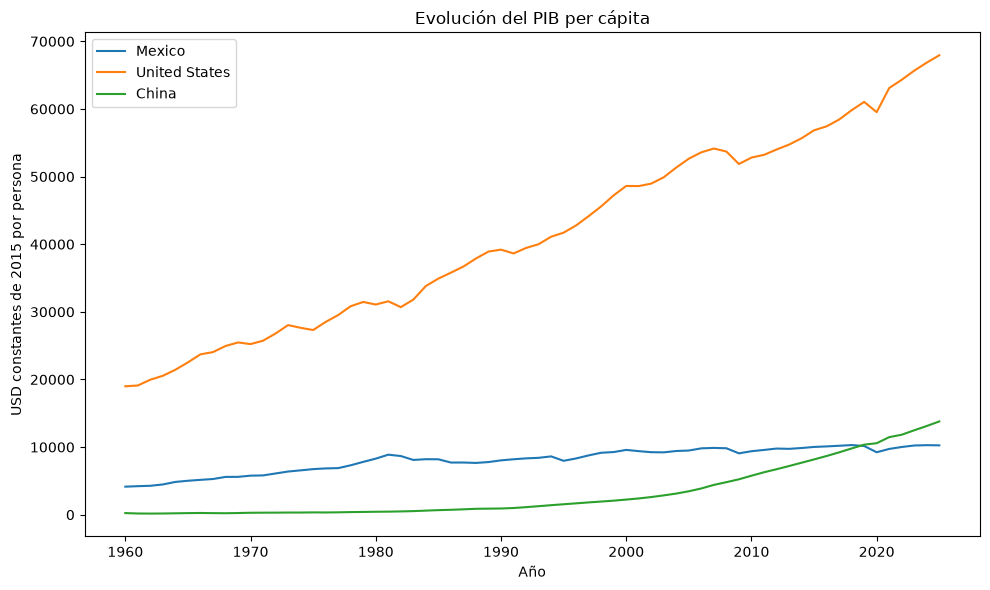

In [17]:
# Pregunta 8
# Tu codigo aqui
paises_grafica = ["Mexico", "United States", "China"]
plt.figure(figsize=(10, 6))
for pais in paises_grafica:
    datos_pais = df_paises[df_paises["entity"] == pais].sort_values("year")
    plt.plot(datos_pais["year"], datos_pais["valor"], label=pais)
plt.title("Evolución del PIB per cápita")
plt.xlabel("Año")
plt.ylabel("USD constantes de 2015 por persona")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:**

Estados Unidos mantiene un PIB per cápita superior al de México y China. México muestra un crecimiento con retrocesos, mientras que China aumenta especialmente en las últimas décadas y supera a México hacia el final de la serie.

### Pregunta 9 — Visualización integradora

Crea dos gráficas de barras (horizontales o verticales) con el Top 10 de países según tu indicador en la primera consulta el año de tu nacimiento, y en la segunda el año 2023, ordenados de mayor a menor.  Qué movimientos hubo en ambas gráficas?
Agrega título y etiquetas de ejes.

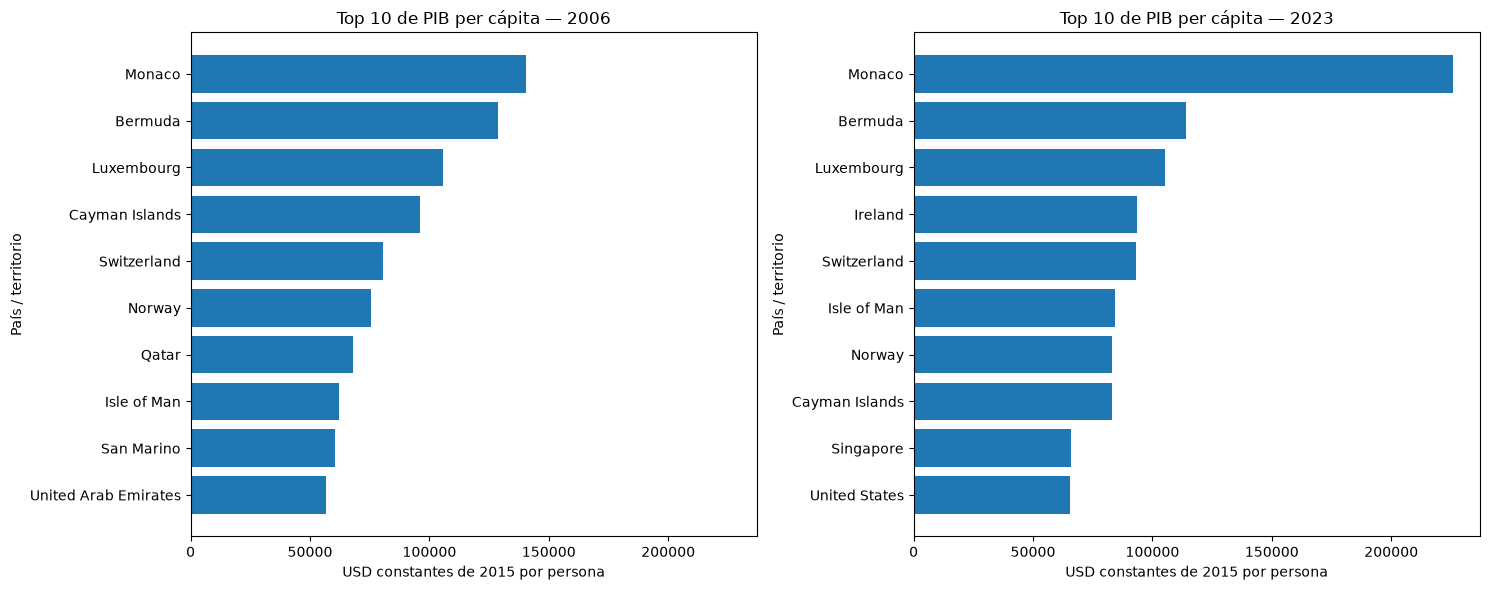

In [18]:
# Pregunta 9
# Tu codigo aqui
# Grafica de barras horizontales
# para que el país con el valor mas alto quede arriba
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, anio in zip(axes, [ANIO_NACIMIENTO, 2023]):
    top = df_paises[df_paises["year"] == anio].dropna(subset=["valor"]).nlargest(10, "valor")
    ax.barh(top["entity"], top["valor"])
    ax.invert_yaxis()
    ax.set_title(f"Top 10 de PIB per cápita — {anio}")
    ax.set_xlabel("USD constantes de 2015 por persona")
    ax.set_ylabel("País / territorio")
plt.tight_layout()
plt.show()

**Interpretación:**

Mónaco ocupa el primer lugar tanto en 2006 como en 2023. Entran al Top 10 Irlanda, Singapur y Estados Unidos; salen Qatar, San Marino y Emiratos Árabes Unidos. Islas Caimán baja del puesto 4 al 8, Isla de Man sube del 8 al 6 y Noruega baja del 6 al 7. Las demás economías presentes en ambos rankings mantienen su posición.

## 5. Conclusión general

En 5 - 10 líneas, resume qué aprendiste sobre el dataset que te tocó trabajar: ¿qué
patrones encontraste?, ¿qué limitaciones tiene la información (por ejemplo, valores
absolutos sin normalizar por población, datos faltantes, etc.)?, ¿qué harías distinto si
tuvieras más tiempo?

El análisis permitió comparar el PIB per cápita real entre economías y a lo largo del tiempo.  
En México, el cambio acumulado entre 1960 y 2025 fue de 147.40%, con crecimiento de largo plazo y retrocesos intermedios.  
Las diferencias entre países son amplias y los valores altos hacen que la media supere a la mediana.  
Los rankings de 2006 y 2023 muestran cambios en la posición relativa de las economías.  
El indicador ya está normalizado por población y ajustado por inflación, pero no por diferencias internacionales del costo de vida.  
Tampoco permite conocer la desigualdad interna, los ingresos individuales ni establecer causas de los cambios.  
La cobertura temporal es desigual y el filtro incluye territorios; los promedios de grupos tienen el mismo peso por país.  
Con más tiempo incorporaría PIB per cápita en paridad de poder adquisitivo, indicadores de desigualdad y una comparación con cobertura constante.

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envia una copia del notebook por teams.
